# Preprocesado final del dataset (sin blur)

Para cada imagen seleccionada de `train` y `val`:

1. Recorte de bordes negros de la lupa
2. Cuadrado central + resize a 512x512
3. Color constancy (Shades of Gray, p=6)
4. Eliminación de pelos (black-hat + filtro de forma + inpainting; mismo código que `preprocessing.py` de la compañera)
5. Segmentación: Otsu sobre el canal S (directamente sobre la imagen sin blur) + limpieza morfológica

Guarda en `processed/{split}/{clase}/`:
- `<nombre>_preprocessed.png` (RGB 512x512, sin blur, PNG sin pérdidas)
- `<nombre>_mask.png` (0/255, uint8, 512x512, alineada con la anterior)

y un `processed/manifest.csv` con una fila por imagen.

El proceso es **reanudable**: si ya existen los dos archivos de una imagen, no se vuelve a procesar.
La selección usa semilla fija y es estratificada por clase y subtipo, con la proporción real del dataset.

In [1]:
import json
import random
import re
import time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# ---------------- Configuración ----------------
ROOT = Path(r"C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\mini_dataset")             # p. ej. Path("C:/Users/.../Melanoma-Challenge-ML-UdG"); None = buscar automáticamente
OUT_DIR = None           # None = ROOT / "processed"
CLASSES = ["nevus", "others"]
N_TRAIN = None           # None = todas
N_VAL = None             # None = todas
SEED = 42
OVERWRITE = False        # True = reprocesa aunque ya existan los archivos
N_JOBS = 4               # núcleos a usar (-1 = todos, -2 = todos menos uno)

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
TARGET_SIZE = 512
DARK_THR = 35
SOG_P = 6

# ---- Eliminación de pelos: mismo código y mismos parámetros que preprocessing.py de la compañera ----
# Cópialos de preprocessing/preproc_params.json -> "hair". Los valores de abajo son los POR DEFECTO de su función.
HAIR = dict(kernel_size=5,            # ancho del kernel black-hat: debe ser mayor que el grosor de los pelos
            thresh=10,                 # valor mínimo del black-hat para contar como pelo
            kernel_shape="cross",      # "cross", "rect", "ellipse" o "lines" (0/45/90/135 grados, DullRazor)
            channel="gray",            # "gray", "L" (Lab) o "max_rgb" (black-hat por canal y máximo)
            blur_ksize=3,              # suavizado del mapa black-hat para unir pelos rotos (1 = sin suavizar)
            filter_shape=True,         # descarta manchas redondas (puntos, bordes de lesión)
            min_elongation=3.0,        # largo/ancho mínimo para considerarlo pelo
            min_area=20,               # área mínima del componente (px a HAIR_REF_SIDE)
            max_fill=0.35,             # componentes "dispersos" (pelos cruzados): área/caja rotada < este valor
            dilate_iter=1,             # cuánto se engrosa la máscara antes de rellenar
            inpaint_radius=5,          # vecindad usada para rellenar (px a HAIR_REF_SIDE)
            inpaint_method="telea")    # "telea" o "ns"
# Ella calibró estos valores con imágenes de 256 px de lado, así que la DETECCIÓN del pelo se hace a ese tamaño
# (la imagen se reduce, se calcula la máscara y se amplía) y el RELLENO se hace en la imagen de TARGET_SIZE.
# Con HAIR_REF_SIDE = TARGET_SIZE se detecta a resolución completa (entonces habría que reajustar los valores).
HAIR_REF_SIDE = 256
SEG_CHANNEL = "S"        # canal para Otsu: "S", "L", "a", "b", "Cr", "gray"

## Selección estratificada (clase x subtipo, proporción real)

In [2]:
def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "train").is_dir() and (p / "val").is_dir():
            return p
    raise FileNotFoundError("No encuentro train/ y val/. Pon ROOT a mano.")


def subtype(path, cls):
    m = re.match(r"[A-Za-z]+", path.stem)
    return m.group(0).lower() if m else cls


def allocate(counts, n):
    """Reparto proporcional (método del mayor resto) que suma exactamente n."""
    total = sum(counts.values())
    exact = {k: n * v / total for k, v in counts.items()}
    alloc = {k: int(np.floor(v)) for k, v in exact.items()}
    rest = n - sum(alloc.values())
    for k in sorted(exact, key=lambda k: exact[k] - alloc[k], reverse=True)[:rest]:
        alloc[k] += 1
    return alloc


def select_images(root, split, n, seed):
    strata = {}
    for c in CLASSES:
        for f in sorted((root / split / c).rglob("*")):
            if f.suffix.lower() in EXTS:
                strata.setdefault((c, subtype(f, c)), []).append(f)
    if n is None:
        return [(split, c, f) for (c, _), fs in strata.items() for f in fs]
    alloc = allocate({k: len(v) for k, v in strata.items()}, n)
    rng = random.Random(seed)
    picked = []
    for k in sorted(strata):
        fs = strata[k][:]
        rng.shuffle(fs)
        picked += [(split, k[0], f) for f in fs[:alloc[k]]]
    return picked


ROOT = Path(ROOT) if ROOT else find_root()
OUT = Path(OUT_DIR) if OUT_DIR else ROOT / "processed"
print("root:", ROOT, "\nout: ", OUT)

jobs = select_images(ROOT, "train", N_TRAIN, SEED) + select_images(ROOT, "val", N_VAL, SEED)
print(f"\nTotal a procesar: {len(jobs)}")
for split in ["train", "val"]:
    cnt = Counter((c, subtype(f, c)) for s, c, f in jobs if s == split)
    print(f"  {split}: {dict(sorted(cnt.items()))}")

root: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\mini_dataset 
out:  C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\mini_dataset\processed

Total a procesar: 3000
  train: {('nevus', 'nev'): 1017, ('others', 'ack'): 84, ('others', 'bcc'): 262, ('others', 'bkl'): 214, ('others', 'def'): 24, ('others', 'mel'): 342, ('others', 'scc'): 44, ('others', 'vac'): 13}
  val: {('nevus', 'nev'): 509, ('others', 'ack'): 46, ('others', 'bcc'): 135, ('others', 'bkl'): 95, ('others', 'def'): 5, ('others', 'mel'): 178, ('others', 'scc'): 21, ('others', 'vac'): 11}


## Funciones del pipeline

In [3]:
# ---------- Paso 1: bordes negros ----------
def valid_mask(img, dark_thr=DARK_THR):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    dark = (gray < dark_thr).astype(np.uint8)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    _, lab = cv2.connectedComponents(dark, connectivity=4)
    border_ids = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))) - {0}
    border = np.isin(lab, list(border_ids)).astype(np.uint8)
    m = max(3, int(0.01 * min(img.shape[:2])))
    border = cv2.dilate(border, np.ones((m, m), np.uint8))
    return border == 0


def largest_rectangle(mask):
    H, W = mask.shape
    heights = [0] * W
    best = (0, 0, H, 0, W)
    for y in range(H):
        row = mask[y]
        heights = [h + 1 if row[x] else 0 for x, h in enumerate(heights)]
        stack = []
        for x in range(W + 1):
            h = heights[x] if x < W else 0
            start = x
            while stack and stack[-1][1] >= h:
                s, sh = stack.pop()
                area = sh * (x - s)
                if area > best[0]:
                    best = (area, y - sh + 1, y + 1, s, x)
                start = s
            stack.append((start, h))
    return best[1:]


def crop_black_borders(img, dark_thr=DARK_THR, min_area_frac=0.08):
    H, W = img.shape[:2]
    mask = valid_mask(img, dark_thr)
    scale = min(1.0, 256 / max(H, W))
    small = cv2.resize(mask.astype(np.uint8), None, fx=scale, fy=scale,
                       interpolation=cv2.INTER_NEAREST).astype(bool)
    y0, y1, x0, x1 = largest_rectangle(small)
    y0, y1 = int(np.ceil(y0 / scale)), int(np.floor(y1 / scale))
    x0, x1 = int(np.ceil(x0 / scale)), int(np.floor(x1 / scale))
    fallback = False
    if (y1 - y0) * (x1 - x0) < min_area_frac * H * W:
        y0, y1, x0, x1 = 0, H, 0, W            # fallback: no se recorta
        fallback = True
    return img[y0:y1, x0:x1], (y0, y1, x0, x1), fallback


# ---------- Paso 2: cuadrado + resize ----------
def square_resize(img, size=TARGET_SIZE):
    H, W = img.shape[:2]
    s = min(H, W)
    y0, x0 = (H - s) // 2, (W - s) // 2
    sq = img[y0:y0 + s, x0:x0 + s]
    interp = cv2.INTER_AREA if s > size else cv2.INTER_CUBIC
    return cv2.resize(sq, (size, size), interpolation=interp)


# ---------- Paso 3: Shades of Gray ----------
def shades_of_gray(img, p=SOG_P):
    x = img.astype(np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p)
    illum = illum / np.linalg.norm(illum)
    out = x / (illum * np.sqrt(3))
    return np.clip(out, 0, 255).astype(np.uint8)


# ---------- Paso 4: pelos (port de preprocessing.py de la compañera; trabaja en BGR como OpenCV) ----------
def _line_kernels(k):
    """Líneas finas a 0, 45, 90 y 135 grados (k x k)."""
    horiz = np.ones((1, k), np.uint8)
    return [horiz, horiz.T.copy(), np.eye(k, dtype=np.uint8), np.fliplr(np.eye(k, dtype=np.uint8)).copy()]


def blackhat_response(img, kernel_size=17, kernel_shape="cross", channel="gray", blur_ksize=3):
    """Mapa black-hat (cierre - imagen): brilla donde hay estructuras oscuras finas más estrechas que el kernel."""
    k = int(kernel_size) | 1
    if channel == "gray":
        chans = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)]
    elif channel == "L":
        chans = [cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0]]
    elif channel == "max_rgb":
        chans = list(cv2.split(img))
    else:
        raise ValueError(f"canal de pelo no soportado: {channel!r}")
    if kernel_shape == "lines":
        kernels = _line_kernels(k)
    else:
        shape = {"cross": cv2.MORPH_CROSS, "rect": cv2.MORPH_RECT, "ellipse": cv2.MORPH_ELLIPSE}[kernel_shape]
        kernels = [cv2.getStructuringElement(shape, (k, k))]
    bh = np.zeros(img.shape[:2], np.uint8)
    for ch in chans:
        for ker in kernels:
            bh = np.maximum(bh, cv2.morphologyEx(ch, cv2.MORPH_BLACKHAT, ker))
    if blur_ksize and blur_ksize > 1:
        b = int(blur_ksize) | 1
        bh = cv2.GaussianBlur(bh, (b, b), 0)
    return bh


def hair_mask_stages(img, kernel_size=17, thresh=10, min_elongation=3.0, min_area=20, max_fill=0.35,
                     kernel_shape="cross", channel="gray", blur_ksize=3, dilate_iter=1, filter_shape=True):
    """Máscara de pelo (0/255) y pasos intermedios: {'blackhat', 'thresholded', 'filtered', 'mask'}."""
    blackhat = blackhat_response(img, kernel_size, kernel_shape, channel, blur_ksize)
    _, raw = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)
    if filter_shape:
        # solo componentes alargados (pelos); las manchas redondas se descartan
        n, labels, stats, _ = cv2.connectedComponentsWithStats(raw, connectivity=8)
        keep = np.zeros(n, bool)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < min_area:
                continue
            x, y, bw, bh = stats[i, :4]
            ys, xs = np.where(labels[y:y + bh, x:x + bw] == i)
            pts = np.column_stack([xs, ys]).astype(np.float32)
            (_, _), (a, b), _ = cv2.minAreaRect(pts)
            long_side = max(a, b)
            elongated = long_side / (min(a, b) + 1e-6) >= min_elongation
            # pelos cruzados (X / Y) no son alargados en conjunto, pero rellenan poco su caja rotada, a diferencia de una mancha
            sparse = stats[i, cv2.CC_STAT_AREA] / (a * b + 1e-6) < max_fill
            if long_side >= kernel_size and (elongated or sparse):
                keep[i] = True
        filtered = (keep[labels] * 255).astype(np.uint8)
    else:
        filtered = raw.copy()
    mask = filtered
    if dilate_iter > 0:
        mask = cv2.dilate(filtered, np.ones((3, 3), np.uint8), iterations=int(dilate_iter))
    return {"blackhat": blackhat, "thresholded": raw, "filtered": filtered, "mask": mask}


_INPAINT = {"telea": cv2.INPAINT_TELEA, "ns": cv2.INPAINT_NS}


def remove_hair(img):
    """img RGB (TARGET_SIZE). Detecta el pelo a HAIR_REF_SIDE (donde se calibraron los parámetros) y rellena a TARGET_SIZE.
    Devuelve (imagen_sin_pelos RGB, máscara 0/1 a TARGET_SIZE)."""
    h, w = img.shape[:2]
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    ratio = HAIR_REF_SIDE / min(h, w) if HAIR_REF_SIDE else 1.0
    small = bgr if ratio == 1.0 else cv2.resize(bgr, (round(w * ratio), round(h * ratio)), interpolation=cv2.INTER_AREA)
    mask_kw = {k: v for k, v in HAIR.items() if k not in ("inpaint_radius", "inpaint_method")}
    m = hair_mask_stages(small, **mask_kw)["mask"]
    if ratio != 1.0:
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_LINEAR)
        m = ((m > 127) * 255).astype(np.uint8)
    radius = max(1, int(round(HAIR["inpaint_radius"] / ratio)))
    clean = cv2.inpaint(bgr, m, radius, _INPAINT[HAIR["inpaint_method"]])
    return cv2.cvtColor(clean, cv2.COLOR_BGR2RGB), (m > 0).astype(np.uint8)


# ---------- Paso 5: segmentación Otsu(canal) sin blur ----------
def get_channel(img, name):
    """Calcula solo el canal pedido (más rápido que calcular todos)."""
    if name == "gray":
        return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    if name in ("L", "a", "b"):
        return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[..., "Lab".index(name)]
    if name == "Cr":
        return cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)[..., 1]
    if name == "S":
        return cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[..., 1]
    raise ValueError(f"Canal no soportado: {name}")


def border_ring(shape, frac=0.08):
    H, W = shape
    m = int(frac * min(H, W))
    ring = np.ones((H, W), bool)
    ring[m:H - m, m:W - m] = False
    return ring


def otsu_mask(ch):
    ch = cv2.normalize(ch, None, 0, 255, cv2.NORM_MINMAX)
    _, bw = cv2.threshold(ch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = bw > 0
    if bw[border_ring(bw.shape)].mean() > 0.5:      # el "foreground" es la clase que menos toca el borde
        bw = ~bw
    return bw


def clean_mask(bw, open_k=5, close_k=15, center_sigma=0.35):
    ell = lambda n: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))
    m = bw.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ell(open_k))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ell(close_k))
    n, lab, stats, cent = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n == 1:
        return np.zeros_like(bw)
    S = m.shape[0]
    c = np.array([m.shape[1] / 2, m.shape[0] / 2])
    score = [stats[i, cv2.CC_STAT_AREA] * np.exp(-(np.linalg.norm(cent[i] - c) / (center_sigma * S)) ** 2)
             for i in range(1, n)]
    best = int(np.argmax(score)) + 1
    m = (lab == best).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled.astype(bool)


def segment(img, channel=SEG_CHANNEL):
    return clean_mask(otsu_mask(get_channel(img, channel)))


# ---------- Control de calidad de la máscara (solo flag, no descarta) ----------
def mask_qc(mask, min_frac=0.01, max_frac=0.60, min_solidity=0.75):
    area_frac = float(mask.mean())
    touches = bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any())
    solidity = np.nan
    if mask.any():
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(cnt))
        solidity = float(cv2.contourArea(cnt) / hull_area) if hull_area > 0 else np.nan
    ok = (min_frac <= area_frac <= max_frac) and not touches and (solidity >= min_solidity)
    return {"mask_area_frac": area_frac, "mask_touches_border": touches,
            "mask_solidity": solidity, "seg_ok": bool(ok)}


# ---------- Pipeline completo ----------
def preprocess(img):
    cropped, rect, fallback = crop_black_borders(img)
    resized = square_resize(cropped)
    color_const = shades_of_gray(resized)
    img_feat, hmask = remove_hair(color_const)       # sin blur
    mask = segment(img_feat)                         # Otsu(S) directo sobre img_feat
    return img_feat, mask, rect, float(hmask.mean()), fallback


def read_rgb(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def write_png(path, arr):
    ok, buf = cv2.imencode(".png", arr)
    if not ok:
        raise IOError(f"No se pudo codificar {path}")
    buf.tofile(str(path))

## (Opcional) Vista previa de pelos antes de procesar todo
Coge una muestra al azar de las imágenes a procesar, se queda con las que más pelo tienen y enseña:
entrada · máscara de pelos (rojo) · resultado. Cambia `HAIR` en la configuración y vuelve a ejecutar esta celda
hasta que te guste. Cambia `seed` para ver otras imágenes.

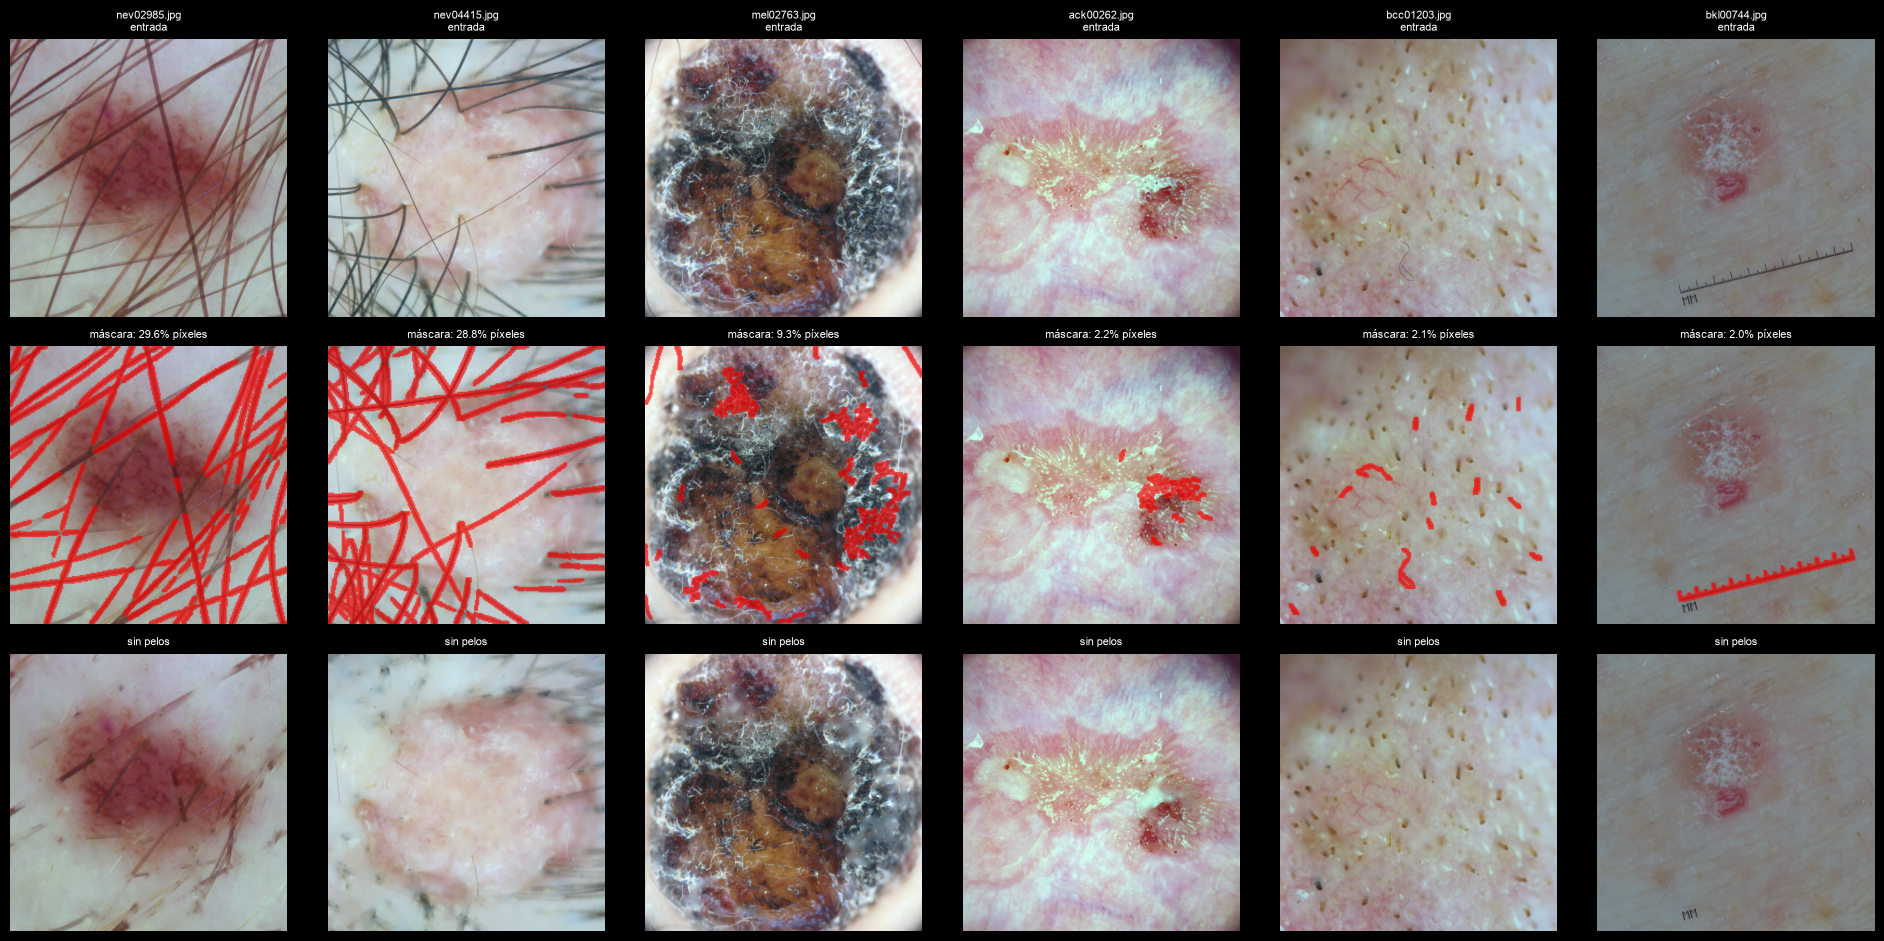

In [4]:
import matplotlib.pyplot as plt


def preview_hair(n=6, pool=30, seed=0):
    rng = random.Random(seed)
    res = []
    for s_, c_, f_ in rng.sample(jobs, min(pool, len(jobs))):
        cropped, _, _ = crop_black_borders(read_rgb(f_))
        cc = shades_of_gray(square_resize(cropped))
        clean, m = remove_hair(cc)
        res.append((m.mean(), f_.name, cc, m, clean))
    res = sorted(res, key=lambda r: -r[0])[:n]
    fig, axs = plt.subplots(3, len(res), figsize=(3.2 * len(res), 9.5), squeeze=False)
    for j, (frac, name, cc, m, clean) in enumerate(res):
        ov = cc.copy()
        ov[m > 0] = (0.35 * ov[m > 0] + 0.65 * np.array([255, 0, 0])).astype(np.uint8)
        for i, (im, t) in enumerate([(cc, f"{name}\nentrada"), (ov, f"máscara: {100 * frac:.1f}% píxeles"), (clean, "sin pelos")]):
            axs[i, j].imshow(im); axs[i, j].set_title(t, fontsize=8); axs[i, j].axis("off")
    plt.tight_layout(); plt.show()


preview_hair()

## Procesado y guardado (paralelo y reanudable)

In [6]:
def process_one(split, cls, path, out_root, overwrite):
    cv2.setNumThreads(1)                              # evita sobresuscripción con joblib
    out_dir = Path(out_root) / split / cls
    out_dir.mkdir(parents=True, exist_ok=True)
    p_img = out_dir / f"{path.stem}_preprocessed.png"
    p_msk = out_dir / f"{path.stem}_mask.png"
    row = {"split": split, "class": cls, "subtype": subtype(path, cls), "name": path.stem,
           "src": str(path), "preprocessed": str(p_img), "mask": str(p_msk)}
    try:
        if p_img.exists() and p_msk.exists() and not overwrite:
            mask = cv2.imdecode(np.fromfile(str(p_msk), np.uint8), cv2.IMREAD_GRAYSCALE) > 0
            row.update(mask_qc(mask))
            row["status"] = "skipped"
            return row
        img = read_rgb(path)
        img_feat, mask, (y0, y1, x0, x1), hair_frac, fallback = preprocess(img)
        write_png(p_img, cv2.cvtColor(img_feat, cv2.COLOR_RGB2BGR))
        write_png(p_msk, (mask.astype(np.uint8) * 255))
        row.update({"orig_h": img.shape[0], "orig_w": img.shape[1],
                    "crop_y0": y0, "crop_y1": y1, "crop_x0": x0, "crop_x1": x1,
                    "crop_fallback": fallback, "hair_frac": hair_frac, **mask_qc(mask), "status": "ok"})
    except Exception as e:                            # una imagen rota no para el lote
        row["status"] = f"error: {e}"
    return row


# Si ya hay imágenes procesadas con OTROS parámetros (o con la versión antigua), no las mezclamos.
PARAMS_JSON = OUT / "preprocess_params.json"
CURRENT = dict(hair=HAIR, hair_ref_side=HAIR_REF_SIDE, hair_method="companera_preprocessing_py_v1", target_size=TARGET_SIZE,
               dark_thr=DARK_THR, sog_p=SOG_P, seg_channel=SEG_CHANNEL)
if not OVERWRITE and any(OUT.rglob("*_preprocessed.png")):
    prev = json.loads(PARAMS_JSON.read_text()) if PARAMS_JSON.exists() else None
    if prev != CURRENT:
        raise RuntimeError("Ya hay imágenes procesadas con otros parámetros (o con la versión antigua del paso de pelos). "
                           "Pon OVERWRITE = True (o borra la carpeta processed/) para rehacerlas todas con los parámetros actuales.")
OUT.mkdir(parents=True, exist_ok=True)
PARAMS_JSON.write_text(json.dumps(CURRENT, indent=2))

t0 = time.time()
gen = Parallel(n_jobs=N_JOBS, return_as="generator")(
    delayed(process_one)(s, c, f, OUT, OVERWRITE) for s, c, f in jobs)
rows = [r for r in tqdm(gen, total=len(jobs))]
print(f"\nTiempo total: {time.time() - t0:.0f}s  ({(time.time() - t0) / max(len(jobs), 1):.2f} s/img de reloj)")

  0%|          | 0/3000 [00:00<?, ?it/s]


Tiempo total: 199s  (0.07 s/img de reloj)


## Manifest y resumen

In [7]:
new = pd.DataFrame(rows)
manifest_path = OUT / "manifest.csv"
if manifest_path.exists():           # conserva datos completos (hair_frac, recorte...) de ejecuciones previas
    old = pd.read_csv(manifest_path)
    new = pd.concat([old, new], ignore_index=True)
    new["_skipped"] = new["status"].eq("skipped")          # las filas 'skipped' tienen menos datos: pierden prioridad
    new = (new.sort_values("_skipped", kind="stable")
              .drop_duplicates(subset=["split", "class", "name"], keep="first")
              .drop(columns="_skipped"))
new = new.sort_values(["split", "class", "name"]).reset_index(drop=True)
new.to_csv(manifest_path, index=False)
print("manifest:", manifest_path, f"({len(new)} filas)\n")

print(new["status"].str.split(":").str[0].value_counts().to_string(), "\n")
print(new.groupby(["split", "class"]).agg(n=("name", "size"),
                                          seg_ok=("seg_ok", "mean"),
                                          area_frac_med=("mask_area_frac", "median"),
                                          hair_frac_med=("hair_frac", "median")).round(3).to_string())

if "crop_fallback" in new:
    print("\nSin recortar (fallback):", int(new["crop_fallback"].fillna(False).sum()))

errs = new[new["status"].str.startswith("error")]
if len(errs):
    print("\nImágenes con error:")
    print(errs[["split", "class", "name", "status"]].to_string(index=False))

manifest: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\mini_dataset\processed\manifest.csv (3000 filas)

status
ok    3000 

                 n  seg_ok  area_frac_med  hair_frac_med
split class                                             
train nevus   1017   0.735          0.164          0.001
      others   983   0.343          0.193          0.003
val   nevus    509   0.770          0.159          0.001
      others   491   0.336          0.197          0.003

Sin recortar (fallback): 0


## (Opcional) Revisión visual rápida: 12 imágenes al azar + las marcadas `seg_ok == False`

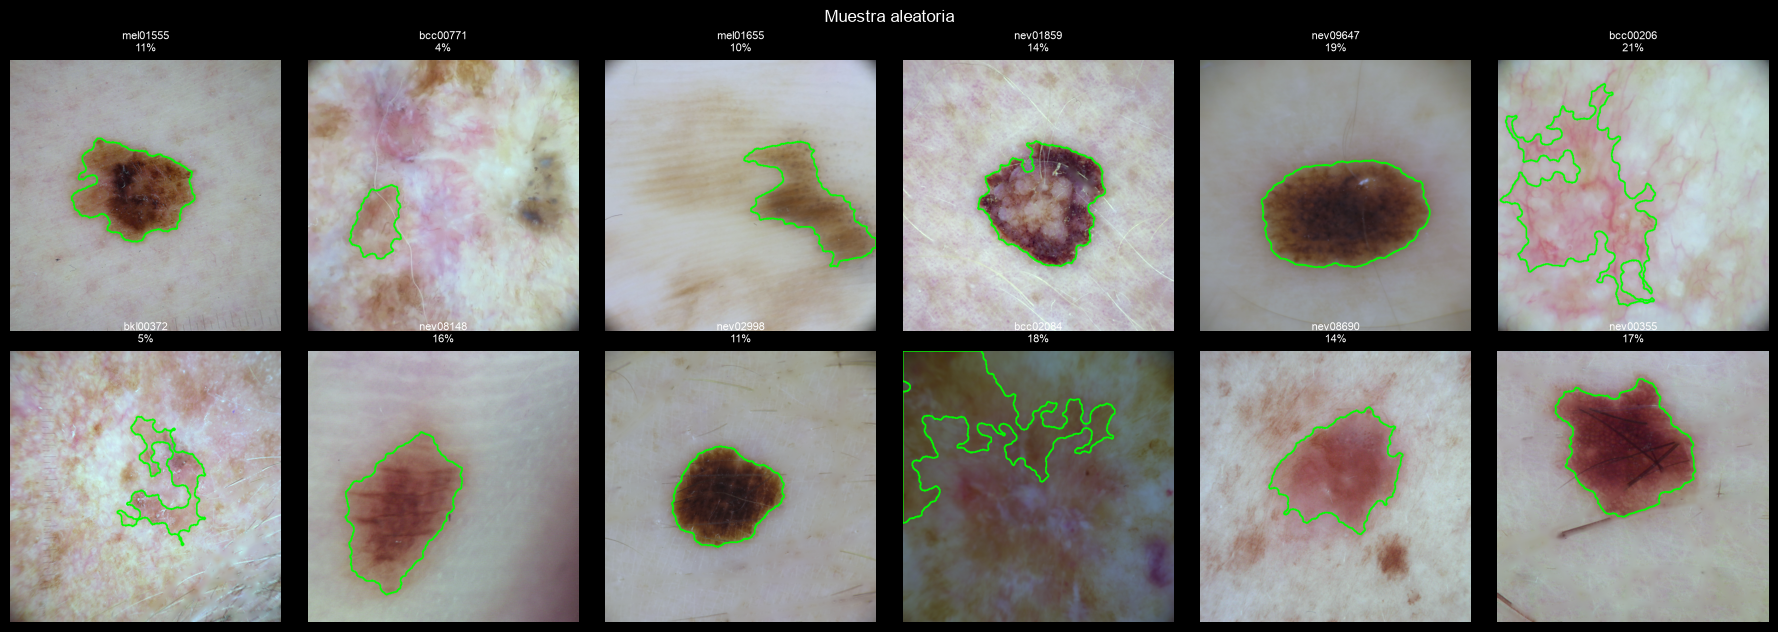

1359 imágenes con seg_ok == False (se muestran hasta 24)


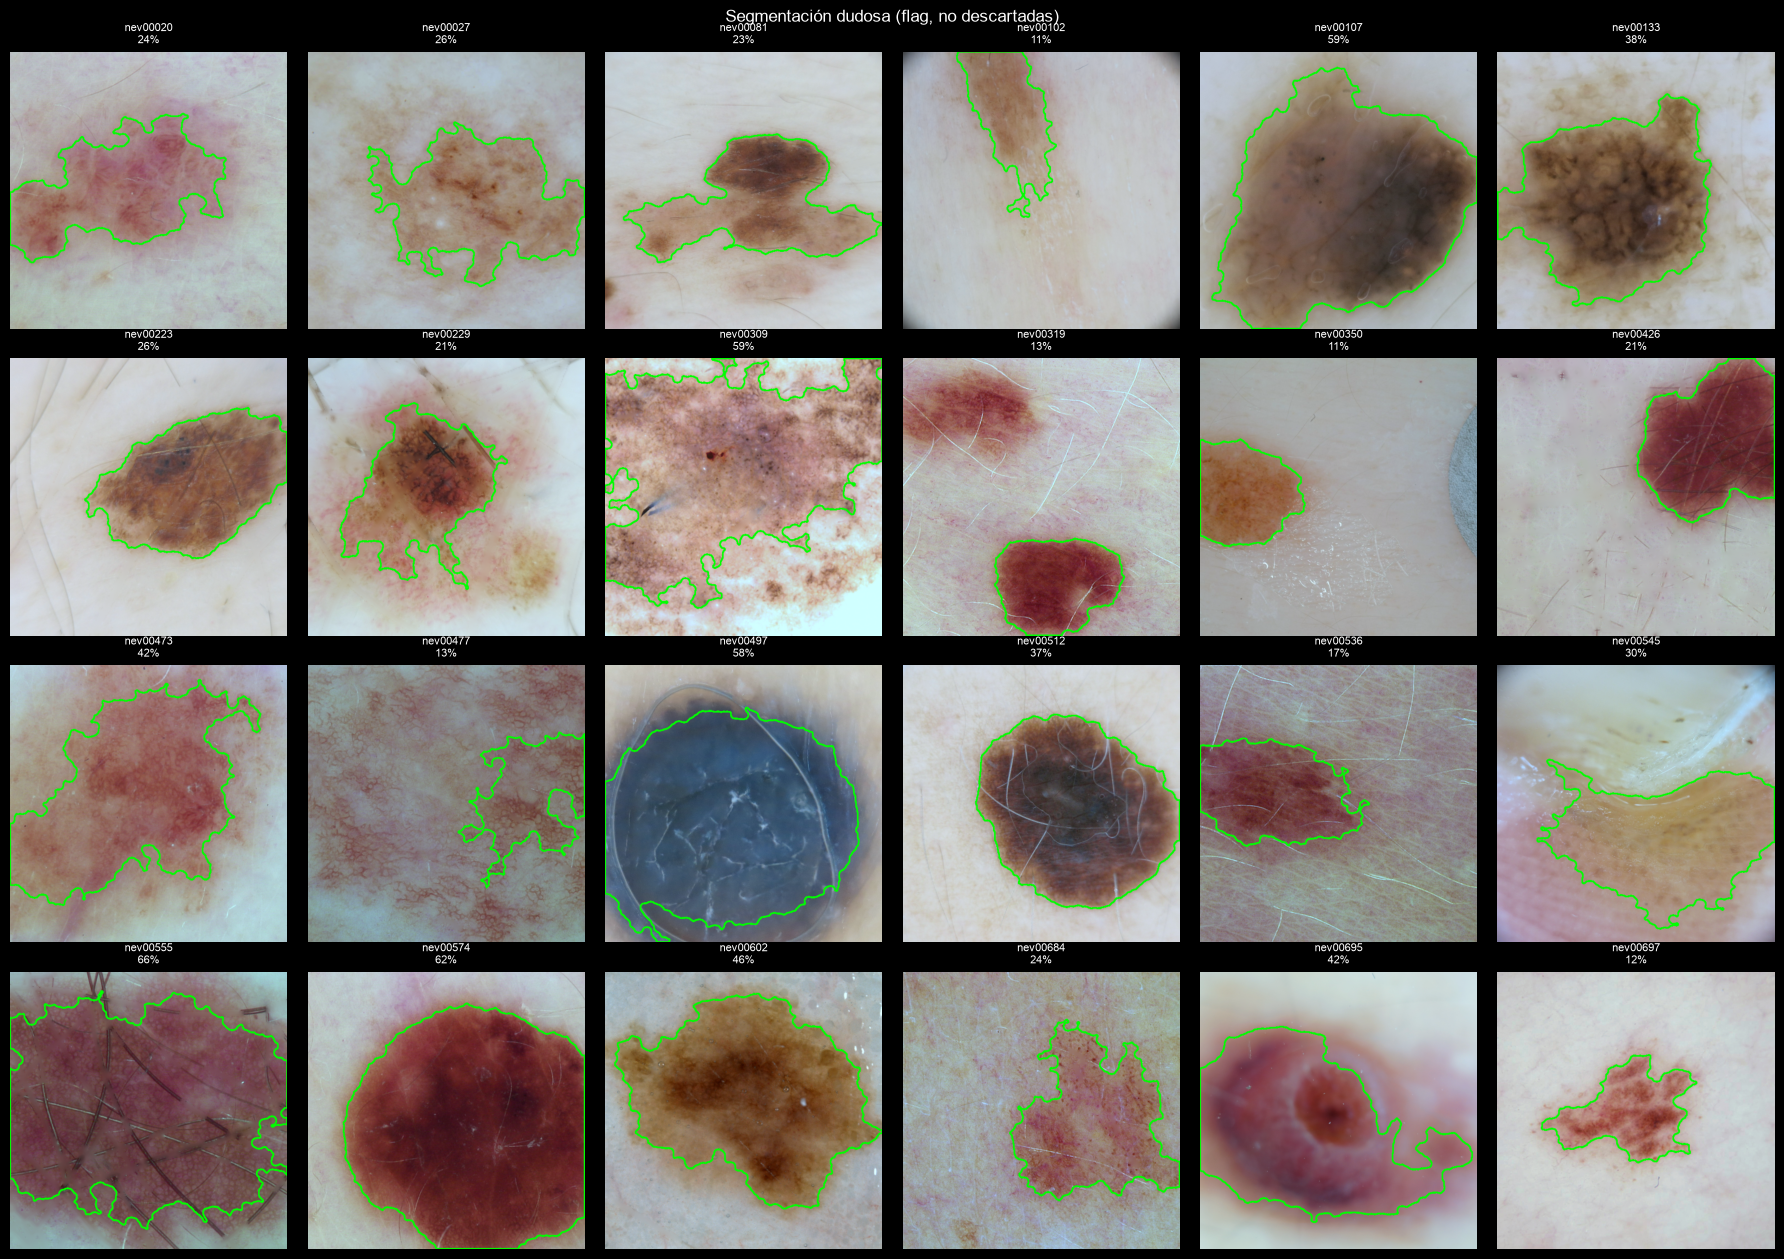

In [8]:
import matplotlib.pyplot as plt


def contour_overlay(img, mask, color=(0, 255, 0), thick=2):
    out = img.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cnts, -1, color, thick)
    return out


def contact_sheet(df, ncols=6, title=""):
    n = len(df)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.2 * nrows), squeeze=False)
    for a in axs.ravel():
        a.axis("off")
    for a, (_, r) in zip(axs.ravel(), df.iterrows()):
        img = read_rgb(r["preprocessed"])
        m = cv2.imdecode(np.fromfile(r["mask"], np.uint8), cv2.IMREAD_GRAYSCALE) > 0
        a.imshow(contour_overlay(img, m))
        a.set_title(f"{r['name']}\n{100 * r['mask_area_frac']:.0f}%", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


ok_rows = new[new["status"].isin(["ok", "skipped"])]
contact_sheet(ok_rows.sample(min(12, len(ok_rows)), random_state=SEED), title="Muestra aleatoria")
bad = ok_rows[~ok_rows["seg_ok"]]
print(f"{len(bad)} imágenes con seg_ok == False (se muestran hasta 24)")
if len(bad):
    contact_sheet(bad.head(24), title="Segmentación dudosa (flag, no descartadas)")